In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d, median_filter
from scipy import interpolate
from scipy.stats import linregress

In [17]:
def phase_detrend(f_GHz, Z):
    phi = np.unwrap(np.angle(Z))
    slope, intercept, *_ = linregress(f_GHz, phi)
    tau = slope / (2*np.pi)           
    trend = np.exp(1j*(2*np.pi*tau*f_GHz + intercept))
    return Z / trend, tau, intercept

def phase_detrend_hz(f_GHz, Z, deg=1):
    f_Hz = np.asarray(f_GHz)*1e9
    phi = np.unwrap(np.angle(Z))
    coefs = np.polyfit(f_Hz, phi, deg=deg)
    poly = np.poly1d(coefs)
    trend = np.exp(1j*poly(f_Hz))
    Z_dt = Z / trend
    return Z_dt, coefs

def coherent_gaussian_smooth(f_GHz, Z, sigma_GHz, half_width=3.5):
    f = np.asarray(f_GHz)
    Z = np.asarray(Z)
    out = np.empty_like(Z, dtype=np.complex128)
    for k in range(len(f)):
        mask = np.abs(f - f[k]) <= half_width*sigma_GHz
        ref = Z[k] / (np.abs(Z[k]) + 1e-15)
        Z_rot = Z[mask] * np.conj(ref)           
        w = np.exp(-0.5*((f[mask]-f[k])/sigma_GHz)**2)
        w /= (w.sum() + 1e-15)
        m = (w * Z_rot).sum()                    
        out[k] = m * ref                        
    return out

def interp_complex(f_src, Z_src, f_tgt, kind="linear", extrapolate=True):
    f_src = np.asarray(f_src)
    Z_src = np.asarray(Z_src)
    f_tgt = np.asarray(f_tgt)
    m = np.isfinite(f_src) & np.isfinite(Z_src.real) & np.isfinite(Z_src.imag)
    f, r, i = f_src[m], Z_src.real[m], Z_src.imag[m]
    if f.size < 2:
        return np.full_like(f_tgt, np.nan, dtype=complex)
    sorted_freqs = np.argsort(f)
    f, r, i = f[sorted_freqs], r[sorted_freqs], i[sorted_freqs]
    f_unique, indices = np.unique(f, return_index=True)
    r, i = r[indices], i[indices]
    f = f_unique

    fill = "extrapolate" if extrapolate else (np.nan, np.nan)

    amp_interp = interpolate.interp1d(f, r, kind=kind, bounds_error=False, fill_value=fill, assume_sorted=True)
    phase_interp = interpolate.interp1d(f, i, kind=kind, bounds_error=False, fill_value=fill, assume_sorted=True)

    return amp_interp(f_tgt) + 1j * phase_interp(f_tgt)

def smooth_complex(Z, sigma_bins):
    return gaussian_filter1d(Z.real, sigma_bins) + 1j * gaussian_filter1d(Z.imag, sigma_bins)

In [18]:
air1 = pd.read_csv("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/Air1_600_to_1200.txt", delimiter="\t").iloc[0:1203]
air2 = pd.read_csv("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/Air2_600_to_1200.txt", delimiter="\t").iloc[0:1203]
air3 = pd.read_csv("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/Air3_600_to_1200.txt", delimiter="\t").iloc[0:1203]
air4 = pd.read_csv("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/Air4_600_to_1200.txt", delimiter="\t").iloc[0:1203]
air5 = pd.read_csv("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/Air5_600_to_1200.txt", delimiter="\t").iloc[0:1203]
AN72_noise = pd.read_csv("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/Noise_600_to_1200.txt", delimiter="\t")


filter_300K =  pd.read_csv("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/300K_600_to_1200.txt", delimiter="\t").iloc[0:1203]
filter_vcs1 = pd.read_csv("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/VCS1_600_to_1200.txt", delimiter="\t").iloc[0:1203]
filter_vcs2 = pd.read_csv("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/VCS2_600_to_1200.txt", delimiter="\t").iloc[0:1203]
filter_4K = pd.read_csv("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/4K_600_to_1200.txt", delimiter="\t").iloc[0:1203]

air1_data = air1[['Frequency Act (GHz)', 'Amplitude (via StrMod)','Phase (via StrMod)', "'WLM1' - 'Aux3 - Timestamp'"]]
air2_data = air2[['Frequency Act (GHz)', 'Amplitude (via StrMod)','Phase (via StrMod)', "'WLM1' - 'Aux3 - Timestamp'"]]
air3_data = air3[['Frequency Act (GHz)', 'Amplitude (via StrMod)','Phase (via StrMod)', "'WLM1' - 'Aux3 - Timestamp'"]]
air4_data = air4[['Frequency Act (GHz)', 'Amplitude (via StrMod)','Phase (via StrMod)', "'WLM1' - 'Aux3 - Timestamp'"]]
air5_data = air5[['Frequency Act (GHz)', 'Amplitude (via StrMod)','Phase (via StrMod)', "'WLM1' - 'Aux3 - Timestamp'"]]
AN72_noise_data = AN72_noise[['Frequency Act (GHz)', 'Amplitude (via StrMod)','Phase (via StrMod)', "'WLM1' - 'Aux3 - Timestamp'"]]


filter_300K_data = filter_300K[['Frequency Act (GHz)', 'Amplitude (via StrMod)', 'Phase (via StrMod)', "'WLM1' - 'Aux3 - Timestamp'"]]
filter_vcs1_data = filter_vcs1[['Frequency Act (GHz)', 'Amplitude (via StrMod)', 'Phase (via StrMod)', "'WLM1' - 'Aux3 - Timestamp'"]]
filter_vcs2_data = filter_vcs2[['Frequency Act (GHz)', 'Amplitude (via StrMod)', 'Phase (via StrMod)', "'WLM1' - 'Aux3 - Timestamp'"]]
filter_4K_data = filter_4K[['Frequency Act (GHz)', 'Amplitude (via StrMod)', 'Phase (via StrMod)', "'WLM1' - 'Aux3 - Timestamp'"]]



air1_phasor = air1_data["Amplitude (via StrMod)"].to_numpy() * np.exp(1j * air1_data["Phase (via StrMod)"].to_numpy())
air2_phasor = air2_data["Amplitude (via StrMod)"].to_numpy() * np.exp(1j * air2_data["Phase (via StrMod)"].to_numpy())
air3_phasor = air3_data["Amplitude (via StrMod)"].to_numpy() * np.exp(1j * air3_data["Phase (via StrMod)"].to_numpy())
air4_phasor = air4_data["Amplitude (via StrMod)"].to_numpy() * np.exp(1j * air4_data["Phase (via StrMod)"].to_numpy())
air5_phasor = air5_data["Amplitude (via StrMod)"].to_numpy() * np.exp(1j * air5_data["Phase (via StrMod)"].to_numpy())
AN72_noise_phasor = AN72_noise_data["Amplitude (via StrMod)"].to_numpy() * np.exp(1j * AN72_noise_data["Phase (via StrMod)"].to_numpy())


filter_300K_data_phasor = filter_300K_data["Amplitude (via StrMod)"].to_numpy()*np.exp(1j* filter_300K_data["Phase (via StrMod)"].to_numpy())
filter_vcs1_data_phasor = filter_vcs1_data["Amplitude (via StrMod)"].to_numpy()*np.exp(1j* filter_vcs1_data["Phase (via StrMod)"].to_numpy())
filter_vcs2_data_phasor = filter_vcs2_data["Amplitude (via StrMod)"].to_numpy()*np.exp(1j* filter_vcs2_data["Phase (via StrMod)"].to_numpy())
filter_4K_data_phasor = filter_4K_data["Amplitude (via StrMod)"].to_numpy()*np.exp(1j* filter_4K_data["Phase (via StrMod)"].to_numpy())

grid_frequencies = air2["Frequency Set (GHz)"]
air1_interp_phasor = interp_complex(air1_data["Frequency Act (GHz)"], air1_phasor, grid_frequencies, kind="linear", extrapolate=True)
air2_interp_phasor = interp_complex(air2_data["Frequency Act (GHz)"], air2_phasor, grid_frequencies, kind="linear", extrapolate=True)
air3_interp_phasor = interp_complex(air3_data["Frequency Act (GHz)"], air3_phasor, grid_frequencies, kind="linear", extrapolate=True)
air4_interp_phasor = interp_complex(air4_data["Frequency Act (GHz)"], air4_phasor, grid_frequencies, kind="linear", extrapolate=True)
air5_interp_phasor = interp_complex(air5_data["Frequency Act (GHz)"], air5_phasor, grid_frequencies, kind="linear", extrapolate=True)
AN72_noise_interp_phasor = interp_complex(AN72_noise_data["Frequency Act (GHz)"], AN72_noise_phasor, grid_frequencies, kind="linear", extrapolate=True)


filter_300K_interp_phasor = interp_complex(filter_300K_data["Frequency Act (GHz)"], filter_300K_data_phasor, grid_frequencies, kind="linear", extrapolate=True)
filter_vcs1_interp_phasor = interp_complex(filter_vcs1_data["Frequency Act (GHz)"], filter_vcs1_data_phasor, grid_frequencies, kind="linear", extrapolate=True)
filter_vcs2_interp_phasor = interp_complex(filter_vcs2_data["Frequency Act (GHz)"], filter_vcs2_data_phasor, grid_frequencies, kind="linear", extrapolate=True)
filter_4K_interp_phasor = interp_complex(filter_4K_data["Frequency Act (GHz)"], filter_4K_data_phasor, grid_frequencies, kind="linear", extrapolate=True)


air1_interp_amp, air1_interp_ph = np.abs(air1_interp_phasor), np.angle(air1_interp_phasor)
air2_interp_amp, air2_interp_ph = np.abs(air2_interp_phasor), np.angle(air2_interp_phasor)
air3_interp_amp, air3_interp_ph = np.abs(air3_interp_phasor), np.angle(air3_interp_phasor)
air4_interp_amp, air4_interp_ph = np.abs(air4_interp_phasor), np.angle(air4_interp_phasor)
air5_interp_amp, air5_interp_ph = np.abs(air5_interp_phasor), np.angle(air5_interp_phasor)
AN72_noise_interp_amp, AN72_noise_interp_ph = np.abs(AN72_noise_interp_phasor), np.angle(AN72_noise_interp_phasor)



filter_300K_interp_amp, filter_300K_interp_ph     = np.abs(filter_300K_interp_phasor), np.angle(filter_300K_interp_phasor)
filter_vcs1_interp_amp, filter_vcs1_interp_ph             = np.abs(filter_vcs1_interp_phasor    ), np.angle(filter_vcs1_interp_phasor    )
filter_vcs2_interp_amp, filter_vcs2_interp_ph             = np.abs(filter_vcs2_interp_phasor    ), np.angle(filter_vcs2_interp_phasor    )
filter_4K_interp_amp, filter_4K_interp_ph               = np.abs(filter_4K_interp_phasor    ), np.angle(filter_4K_interp_phasor    )

# Alref = (1/7)*(Al1_interp_phasor + Al2_interp_phasor + Al3_interp_phasor + Al4_interp_phasor + Al5_interp_phasor + Al6_interp_phasor+ Al7_interp_phasor)

# Alref_dt, coefs = phase_detrend_hz(grid_frequencies, Alref, deg=3) 

air1_dt_phasor = air1_interp_phasor / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, air1_interp_phasor, deg=1)[1])(grid_frequencies * 1e9))
air2_dt_phasor = air2_interp_phasor / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, air2_interp_phasor, deg=1)[1])(grid_frequencies * 1e9))
air3_dt_phasor = air3_interp_phasor / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, air3_interp_phasor, deg=1)[1])(grid_frequencies * 1e9))
air4_dt_phasor = air4_interp_phasor / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, air4_interp_phasor, deg=1)[1])(grid_frequencies * 1e9))
air5_dt_phasor = air5_interp_phasor / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, air5_interp_phasor, deg=1)[1])(grid_frequencies * 1e9))
AN72_noise_dt_phasor = AN72_noise_interp_phasor / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, AN72_noise_interp_phasor, deg=1)[1])(grid_frequencies * 1e9))


sigma_GHz = 20
filter_300K_dt_phasor = filter_300K_interp_phasor/ np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, filter_300K_interp_phasor, deg=1)[1])(grid_frequencies * 1e9))
filter_vcs1_dt_phasor     = filter_vcs1_interp_phasor    / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, filter_vcs1_interp_phasor    , deg=1)[1])(grid_frequencies * 1e9))
filter_vcs2_dt_phasor      = filter_vcs2_interp_phasor     / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, filter_vcs2_interp_phasor     , deg=1)[1])(grid_frequencies * 1e9))
filter_4K_dt_phasor     = filter_4K_interp_phasor    / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, filter_4K_interp_phasor    , deg=1)[1])(grid_frequencies * 1e9))

filter_300K_smooth = coherent_gaussian_smooth(grid_frequencies, filter_300K_dt_phasor, sigma_GHz)
filter_vcs1_smooth     = coherent_gaussian_smooth(grid_frequencies, filter_vcs1_dt_phasor    , sigma_GHz)
filter_vcs2_smooth      = coherent_gaussian_smooth(grid_frequencies, filter_vcs2_dt_phasor     , sigma_GHz)
filter_4K_smooth     = coherent_gaussian_smooth(grid_frequencies, filter_4K_dt_phasor    , sigma_GHz)




air2_smooth = coherent_gaussian_smooth(grid_frequencies, air2_dt_phasor, sigma_GHz)
air1_smooth = coherent_gaussian_smooth(grid_frequencies, air1_dt_phasor, sigma_GHz)
air3_smooth = coherent_gaussian_smooth(grid_frequencies, air3_dt_phasor, sigma_GHz)
air4_smooth = coherent_gaussian_smooth(grid_frequencies, air4_dt_phasor, sigma_GHz)
air5_smooth = coherent_gaussian_smooth(grid_frequencies, air5_dt_phasor, sigma_GHz)
AN72_noise_smooth = coherent_gaussian_smooth(grid_frequencies, AN72_noise_dt_phasor, sigma_GHz)

sigma_bins = 15

air2_smooth_amps = gaussian_filter1d(air2_interp_amp, sigma_bins)
air1_smooth_amps = gaussian_filter1d(air1_interp_amp, sigma_bins)
air3_smooth_amps = gaussian_filter1d(air3_interp_amp, sigma_bins)
air4_smooth_amps = gaussian_filter1d(air4_interp_amp, sigma_bins)
air5_smooth_amps = gaussian_filter1d(air5_interp_amp, sigma_bins)
AN72_noise_smooth_amps = gaussian_filter1d(AN72_noise_interp_amp, sigma_bins)

filter_300K_smooth_amps = gaussian_filter1d(filter_300K_interp_amp, sigma_bins)
filter_vcs1_smooth_amps = gaussian_filter1d(filter_vcs1_interp_amp, sigma_bins)
filter_vcs2_smooth_amps = gaussian_filter1d(filter_vcs2_interp_amp, sigma_bins)
filter_4K_smooth_amps = gaussian_filter1d(filter_4K_interp_amp, sigma_bins)


u_list = [
    pd.to_datetime(np.abs(air1_data["'WLM1' - 'Aux3 - Timestamp'"]).iloc[0], unit='s'),
    pd.to_datetime(np.abs(air2_data["'WLM1' - 'Aux3 - Timestamp'"]).iloc[0], unit='s'),
    pd.to_datetime(np.abs(air3_data["'WLM1' - 'Aux3 - Timestamp'"]).iloc[0], unit='s'),
    pd.to_datetime(np.abs(air4_data["'WLM1' - 'Aux3 - Timestamp'"]).iloc[0], unit='s'), 
    pd.to_datetime(np.abs(air5_data["'WLM1' - 'Aux3 - Timestamp'"]).iloc[0], unit='s'),
]

t_list = [
    pd.to_datetime(np.abs(filter_300K_data["'WLM1' - 'Aux3 - Timestamp'"]).iloc[0], unit='s'),
    pd.to_datetime(np.abs(filter_vcs1_data["'WLM1' - 'Aux3 - Timestamp'"]).iloc[0], unit='s'),
    pd.to_datetime(np.abs(filter_vcs2_data["'WLM1' - 'Aux3 - Timestamp'"]).iloc[0], unit='s'),
    pd.to_datetime(np.abs(filter_4K_data["'WLM1' - 'Aux3 - Timestamp'"]).iloc[0], unit='s'),
    pd.to_datetime(np.abs(AN72_noise_data["'WLM1' - 'Aux3 - Timestamp'"]).iloc[0], unit='s')
]

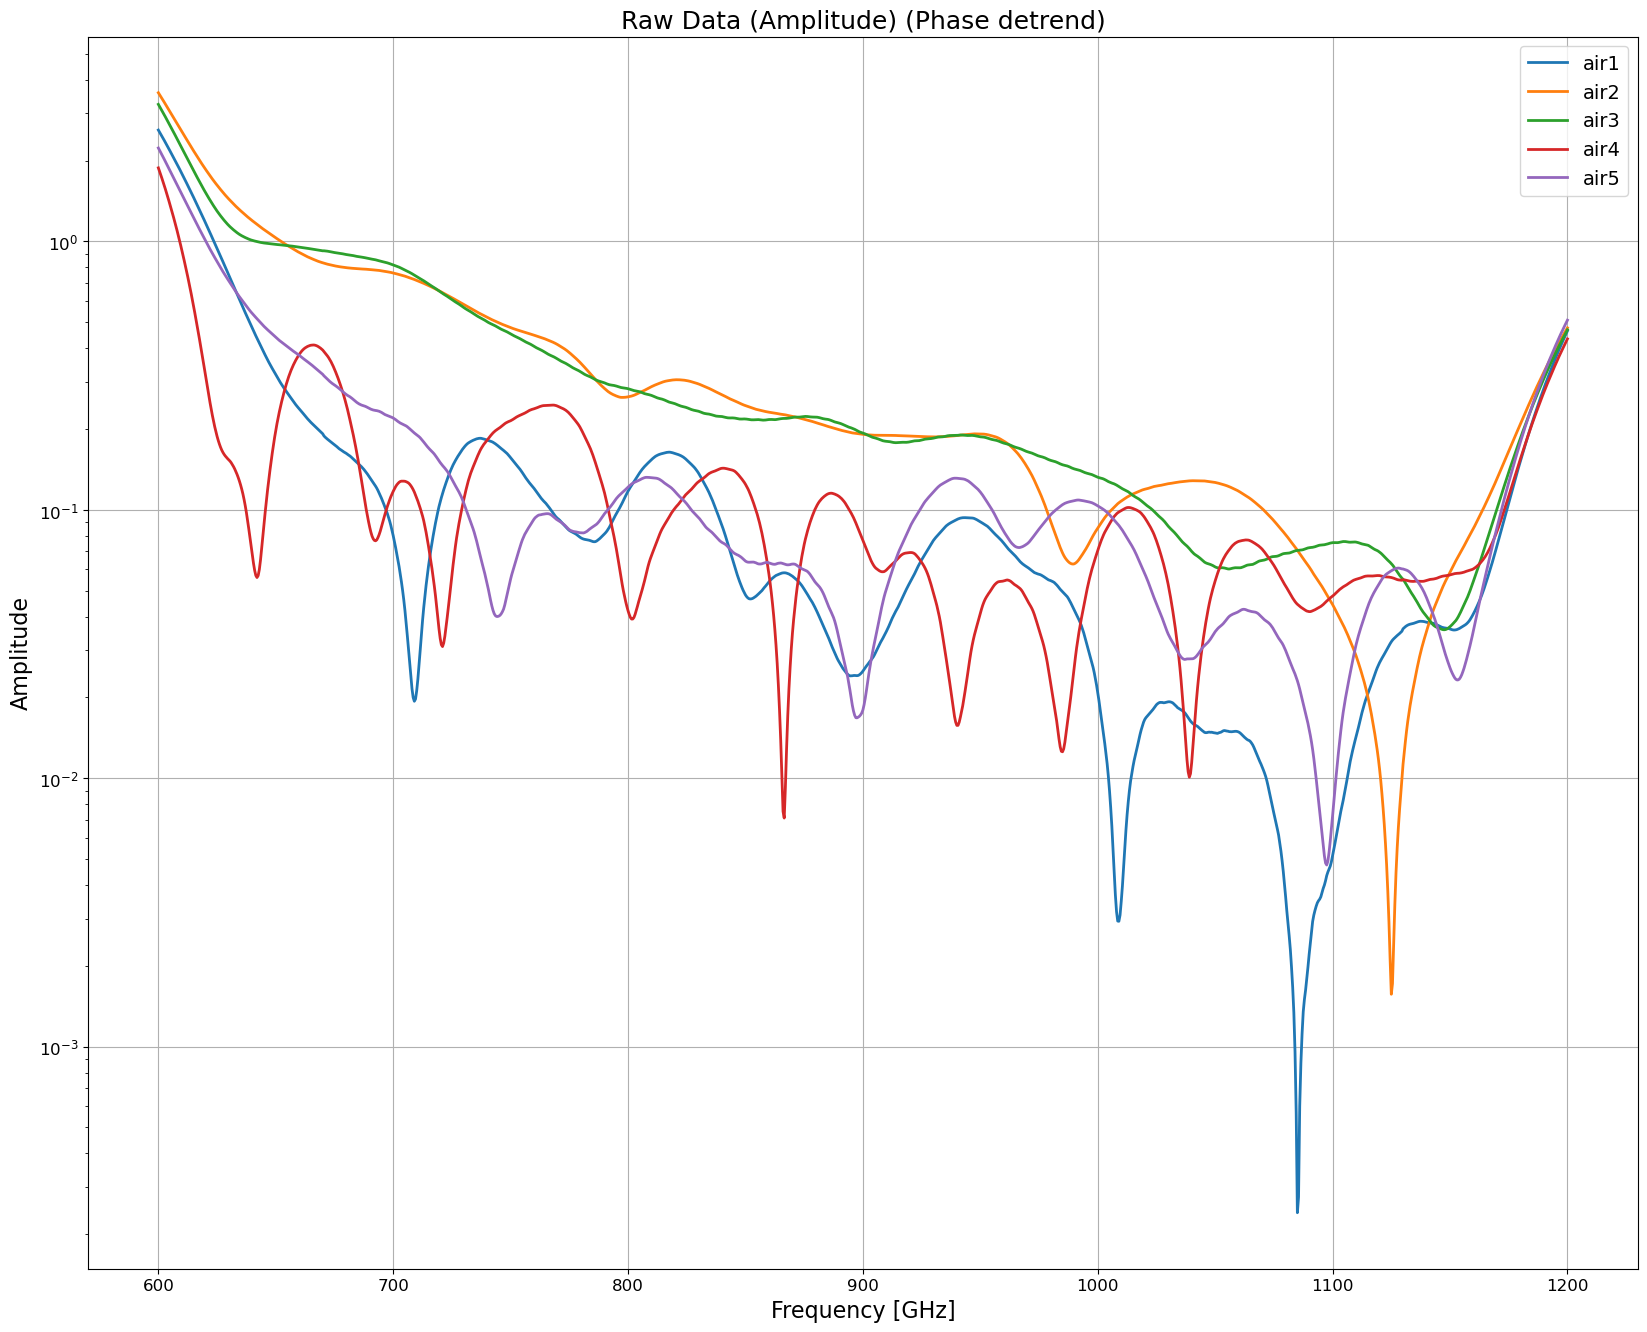

In [19]:
plt.figure(figsize=(20,16))
plt.semilogy(grid_frequencies, np.abs(air1_smooth), label="air1", lw=2)
plt.semilogy(grid_frequencies, np.abs(air2_smooth), label="air2", lw=2)
plt.semilogy(grid_frequencies, np.abs(air3_smooth), label="air3", lw=2)
plt.semilogy(grid_frequencies, np.abs(air4_smooth), label="air4", lw=2)
plt.semilogy(grid_frequencies, np.abs(air5_smooth), label="air5", lw=2)


plt.legend(fontsize=14)
plt.xlabel("Frequency [GHz]", fontsize = 16)
plt.ylabel(r"Amplitude", fontsize = 16)
plt.title("Raw Data (Amplitude) (Phase detrend)", fontsize = 18)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
plt.show()

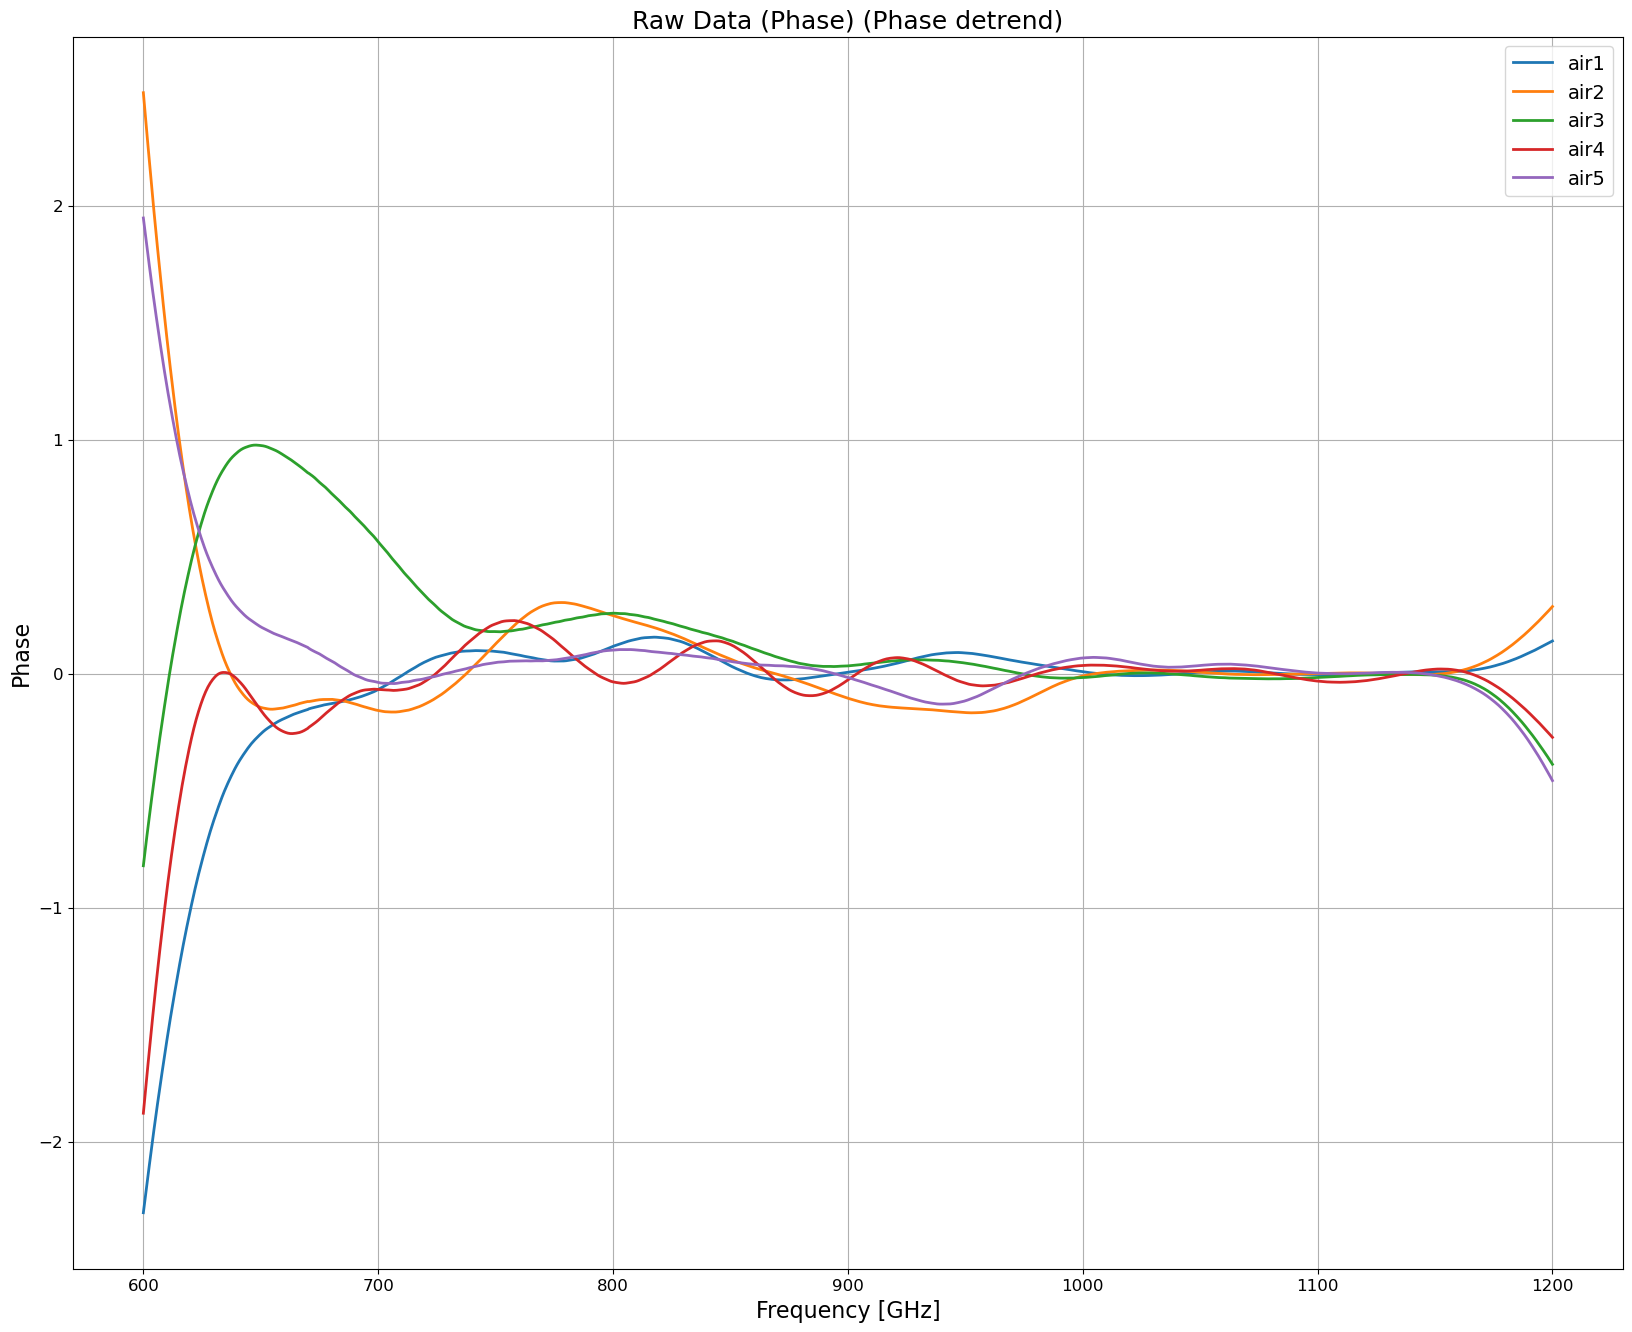

In [20]:
plt.figure(figsize=(20,16))
plt.plot(grid_frequencies, (air1_smooth.imag), label="air1", lw=2)
plt.plot(grid_frequencies, (air2_smooth.imag), label="air2", lw=2)
plt.plot(grid_frequencies, (air3_smooth.imag), label="air3", lw=2)
plt.plot(grid_frequencies, (air4_smooth.imag), label="air4", lw=2)
plt.plot(grid_frequencies, (air5_smooth.imag), label="air5", lw=2)




plt.legend(fontsize=14)
plt.xlabel("Frequency [GHz]", fontsize = 16)
plt.ylabel(r"Phase", fontsize = 16)
plt.title("Raw Data (Phase) (Phase detrend)", fontsize = 18)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
plt.show()

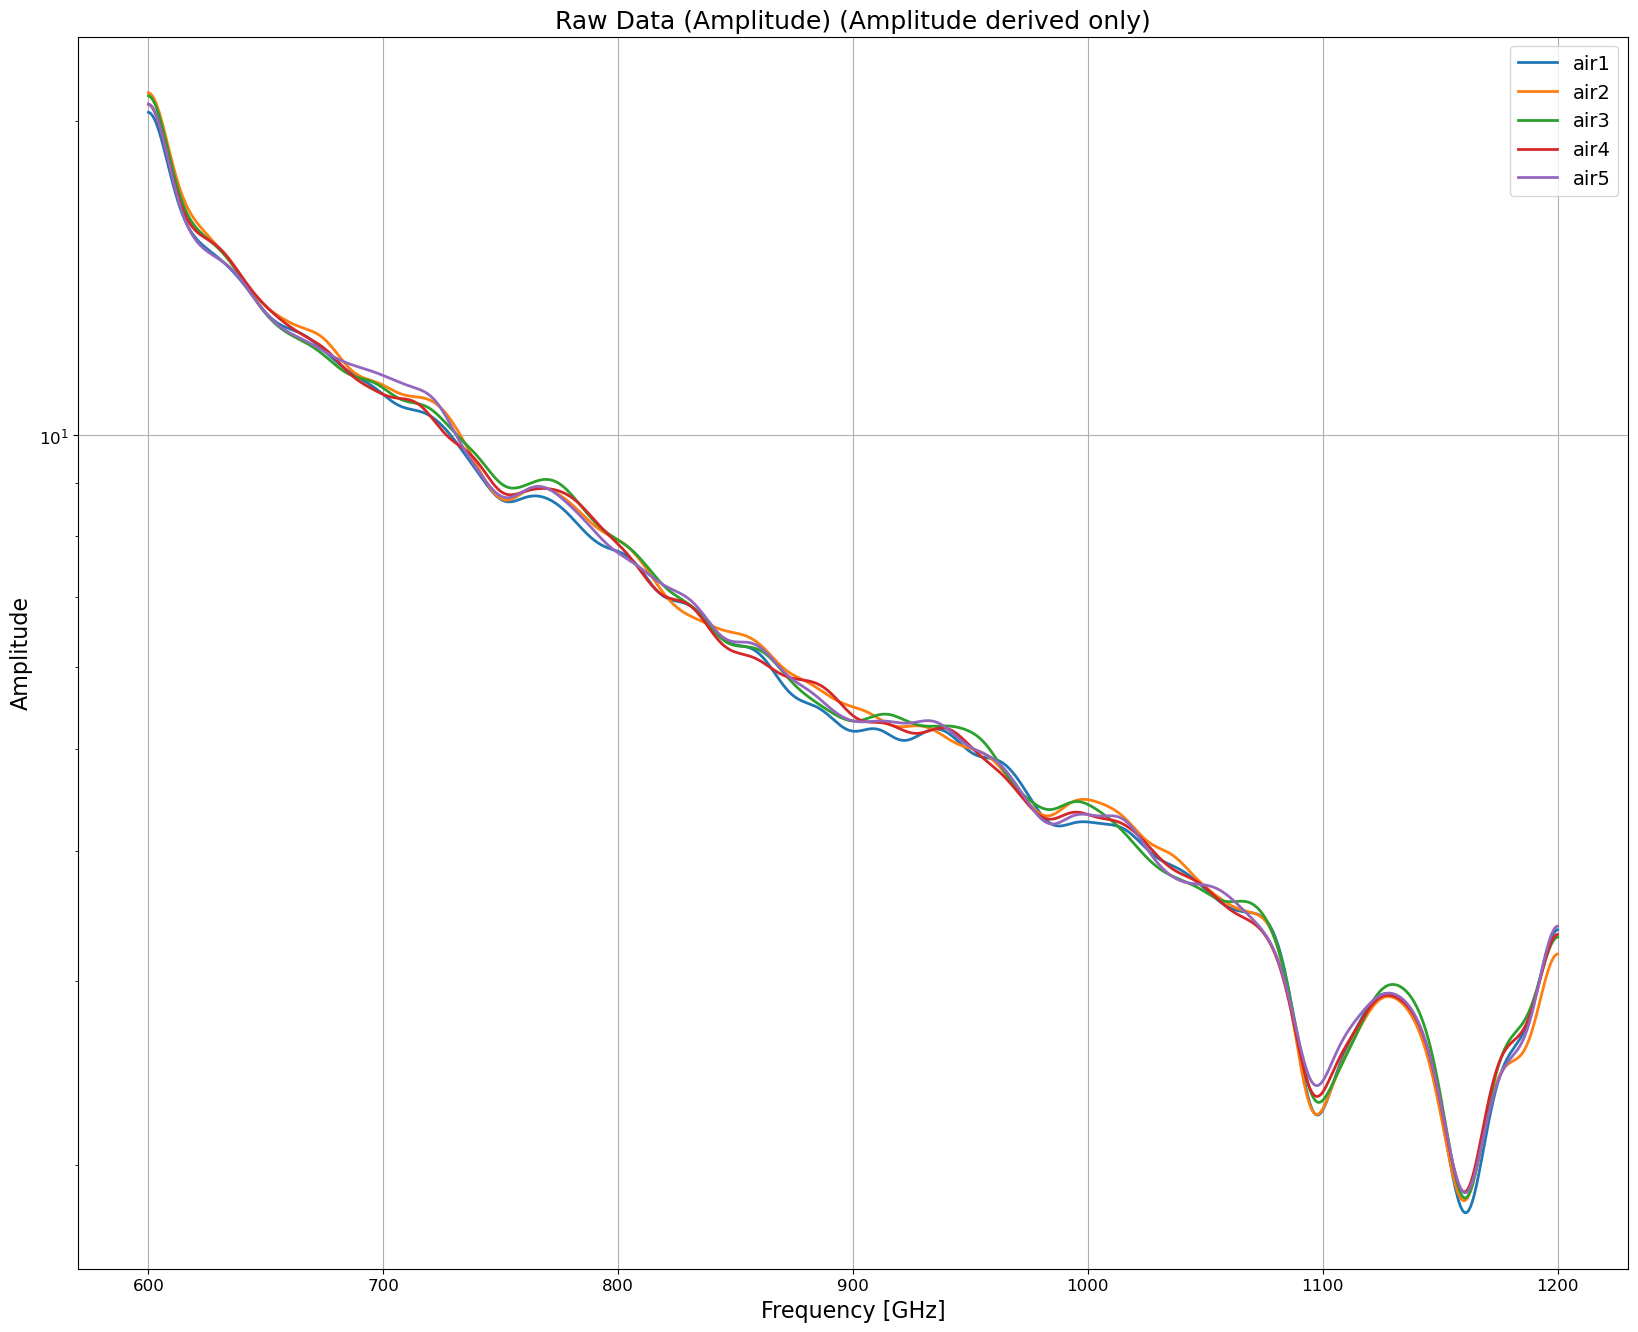

In [21]:
plt.figure(figsize=(20,16))
plt.semilogy(grid_frequencies, np.abs(air1_smooth_amps), label="air1", lw=2)
plt.semilogy(grid_frequencies, np.abs(air2_smooth_amps), label="air2", lw=2)
plt.semilogy(grid_frequencies, np.abs(air3_smooth_amps), label="air3", lw=2)
plt.semilogy(grid_frequencies, np.abs(air4_smooth_amps), label="air4", lw=2)
plt.semilogy(grid_frequencies, np.abs(air5_smooth_amps), label="air5", lw=2)



plt.legend(fontsize=14)
plt.xlabel("Frequency [GHz]", fontsize = 16)
plt.ylabel(r"Amplitude", fontsize = 16)
plt.title("Raw Data (Amplitude) (Amplitude derived only)", fontsize = 18)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
plt.show()

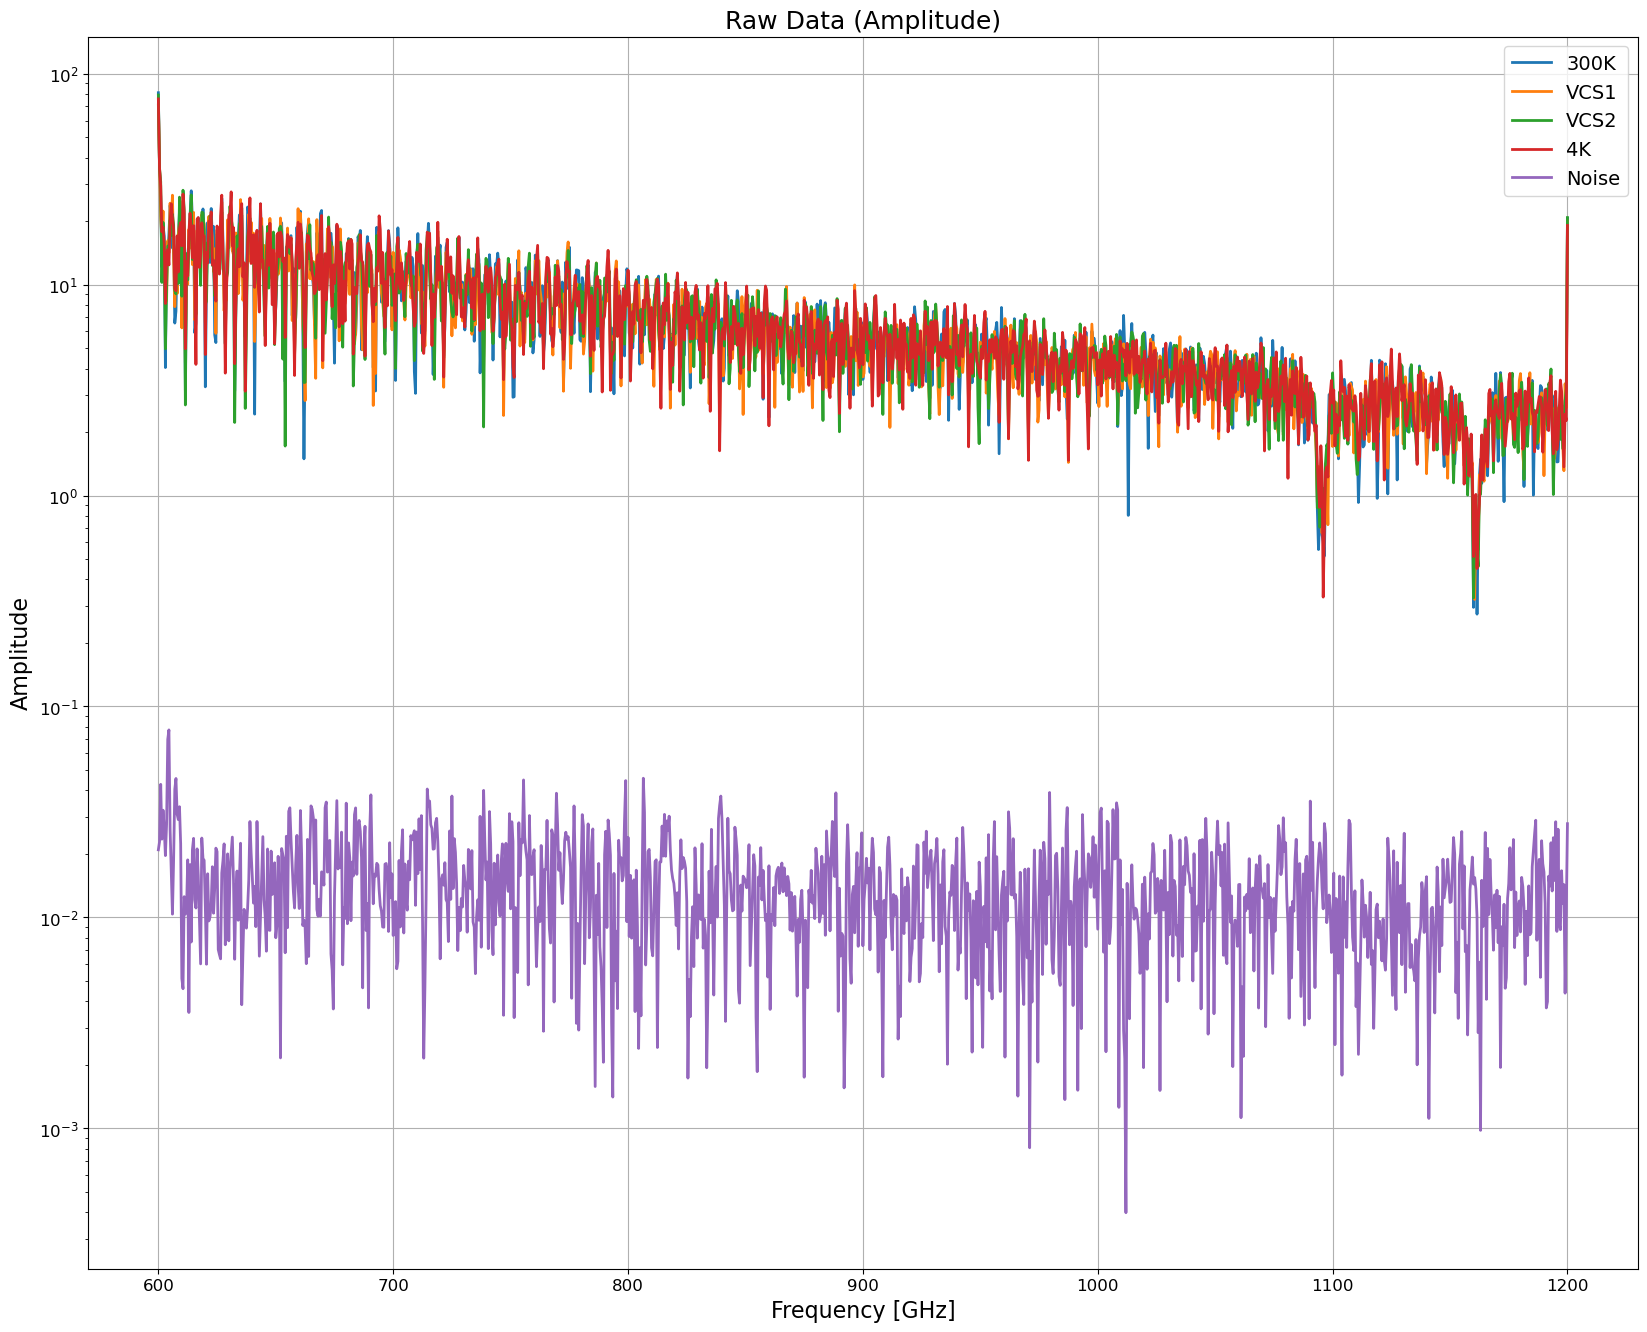

In [22]:
plt.figure(figsize=(20,16))
plt.semilogy(grid_frequencies, np.abs(filter_300K_interp_phasor), label="300K", lw=2)
plt.semilogy(grid_frequencies, np.abs(filter_vcs1_interp_phasor), label="VCS1", lw=2)
plt.semilogy(grid_frequencies, np.abs(filter_vcs2_interp_phasor), label="VCS2", lw=2)
plt.semilogy(grid_frequencies, np.abs(filter_4K_interp_phasor), label="4K", lw=2)
plt.semilogy(grid_frequencies, np.abs(AN72_noise_interp_phasor), label="Noise", lw=2)

plt.legend(fontsize=14)
plt.xlabel("Frequency [GHz]", fontsize = 16)
plt.ylabel(r"Amplitude", fontsize = 16)
plt.title("Raw Data (Amplitude)", fontsize = 18)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
plt.show()

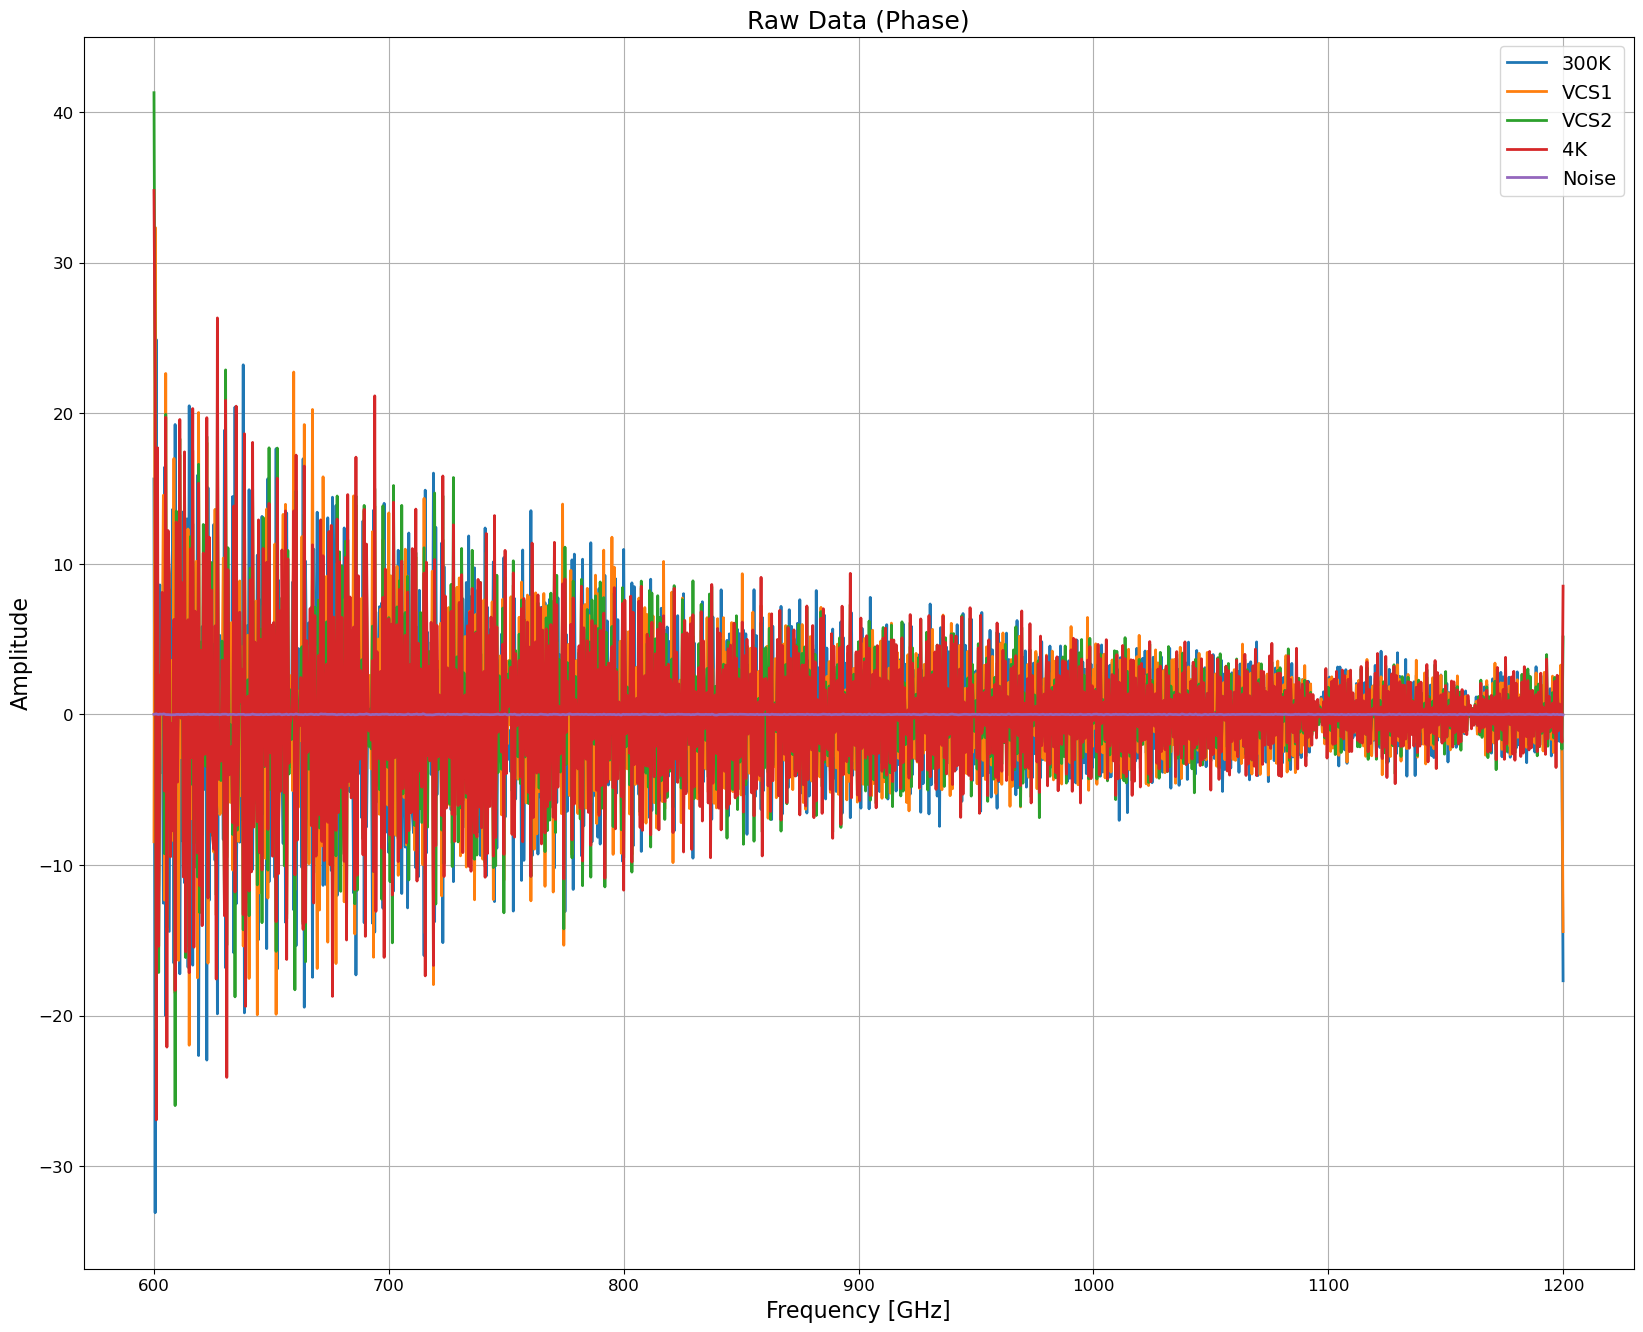

In [23]:
plt.figure(figsize=(20,16))
plt.plot(grid_frequencies, (filter_300K_interp_phasor.imag), label="300K", lw=2)
plt.plot(grid_frequencies, (filter_vcs1_interp_phasor.imag), label="VCS1", lw=2)
plt.plot(grid_frequencies, (filter_vcs2_interp_phasor.imag), label="VCS2", lw=2)
plt.plot(grid_frequencies, (filter_4K_interp_phasor.imag), label="4K", lw=2)
plt.plot(grid_frequencies, (AN72_noise_interp_phasor.imag), label="Noise", lw=2)



plt.legend(fontsize=14)
plt.xlabel("Frequency [GHz]", fontsize = 16)
plt.ylabel(r"Amplitude", fontsize = 16)
plt.title("Raw Data (Phase)", fontsize = 18)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
plt.show()

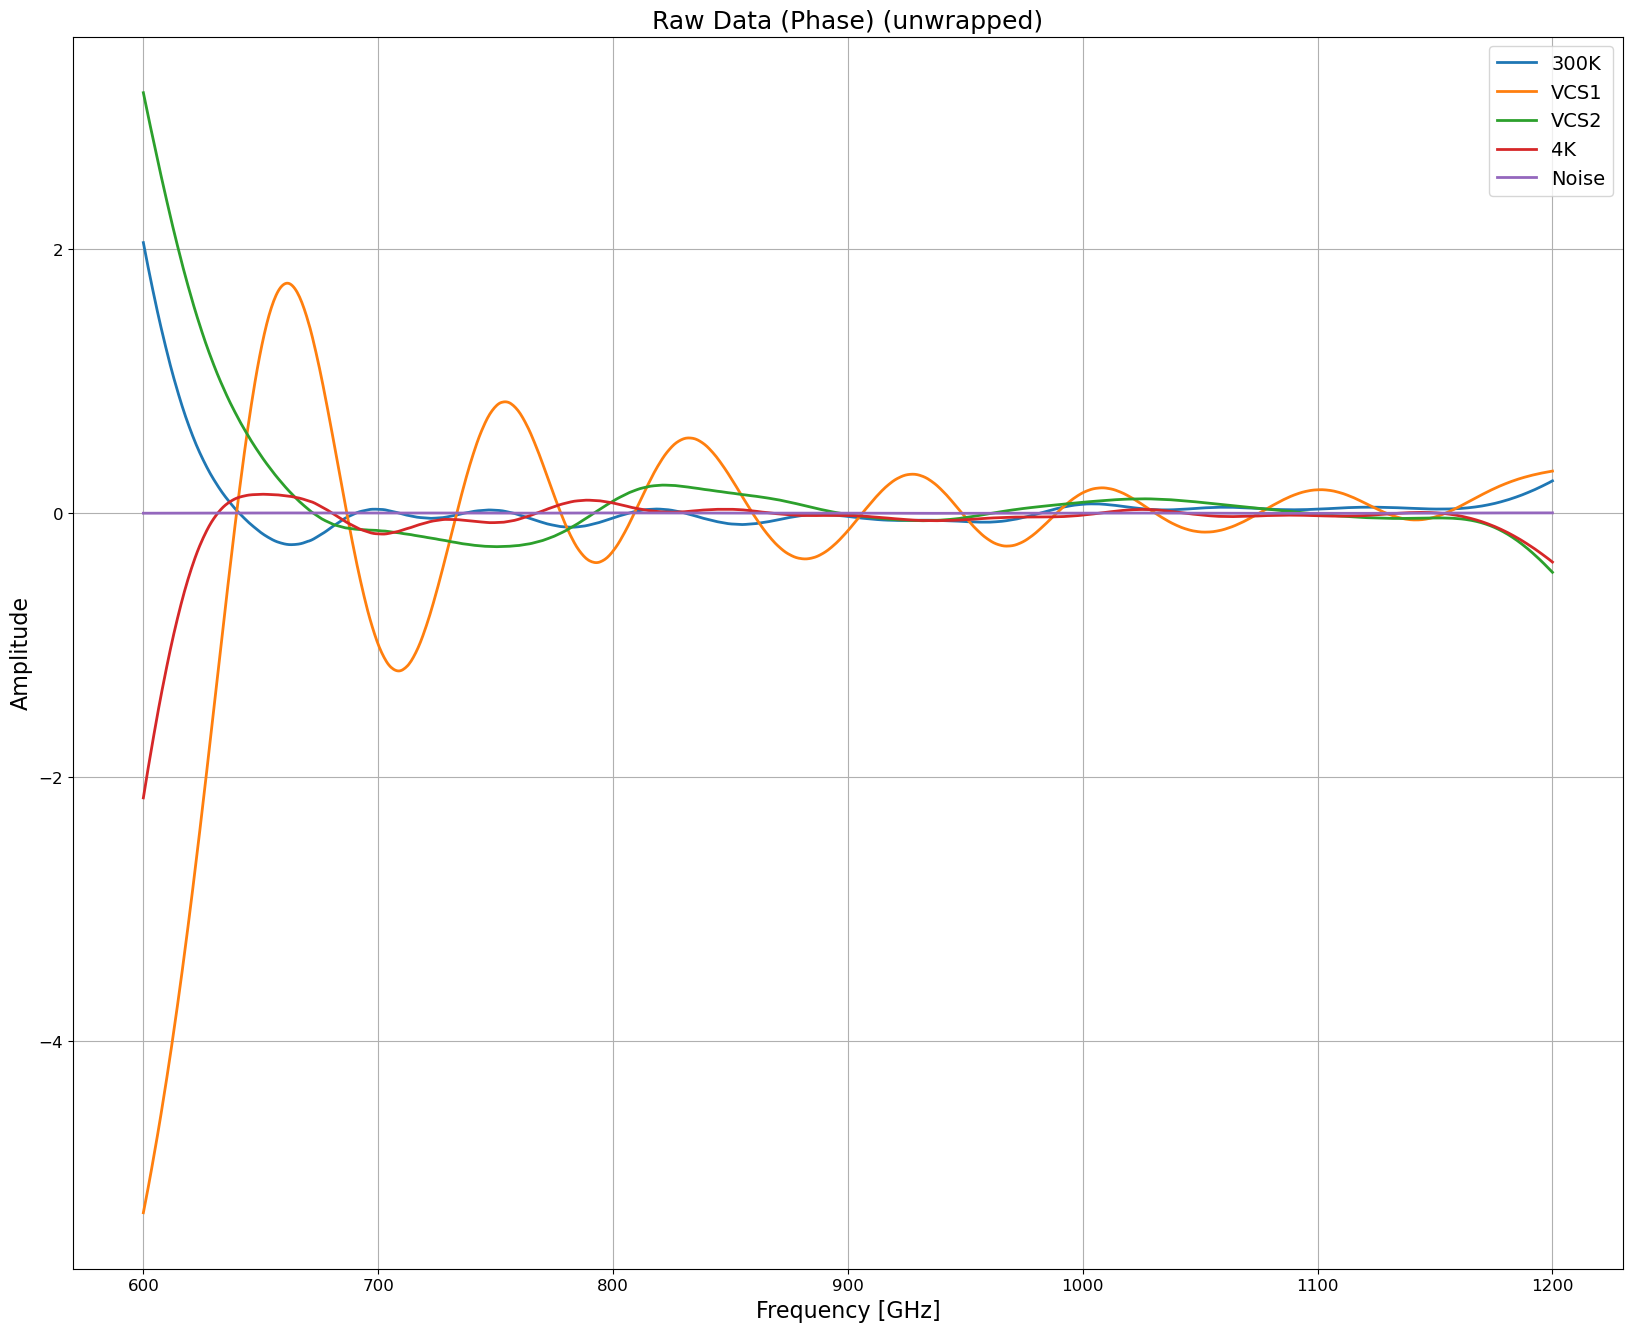

In [24]:
plt.figure(figsize=(20,16))
plt.plot(grid_frequencies, (filter_300K_smooth.imag), label="300K", lw=2)
plt.plot(grid_frequencies, (filter_vcs1_smooth.imag), label="VCS1", lw=2)
plt.plot(grid_frequencies, (filter_vcs2_smooth.imag), label="VCS2", lw=2)
plt.plot(grid_frequencies, (filter_4K_smooth.imag), label="4K", lw=2)
plt.plot(grid_frequencies, (AN72_noise_smooth.imag), label="Noise", lw=2)



plt.legend(fontsize=14)
plt.xlabel("Frequency [GHz]", fontsize = 16)
plt.ylabel(r"Amplitude", fontsize = 16)
plt.title("Raw Data (Phase) (unwrapped)", fontsize = 18)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
plt.show()

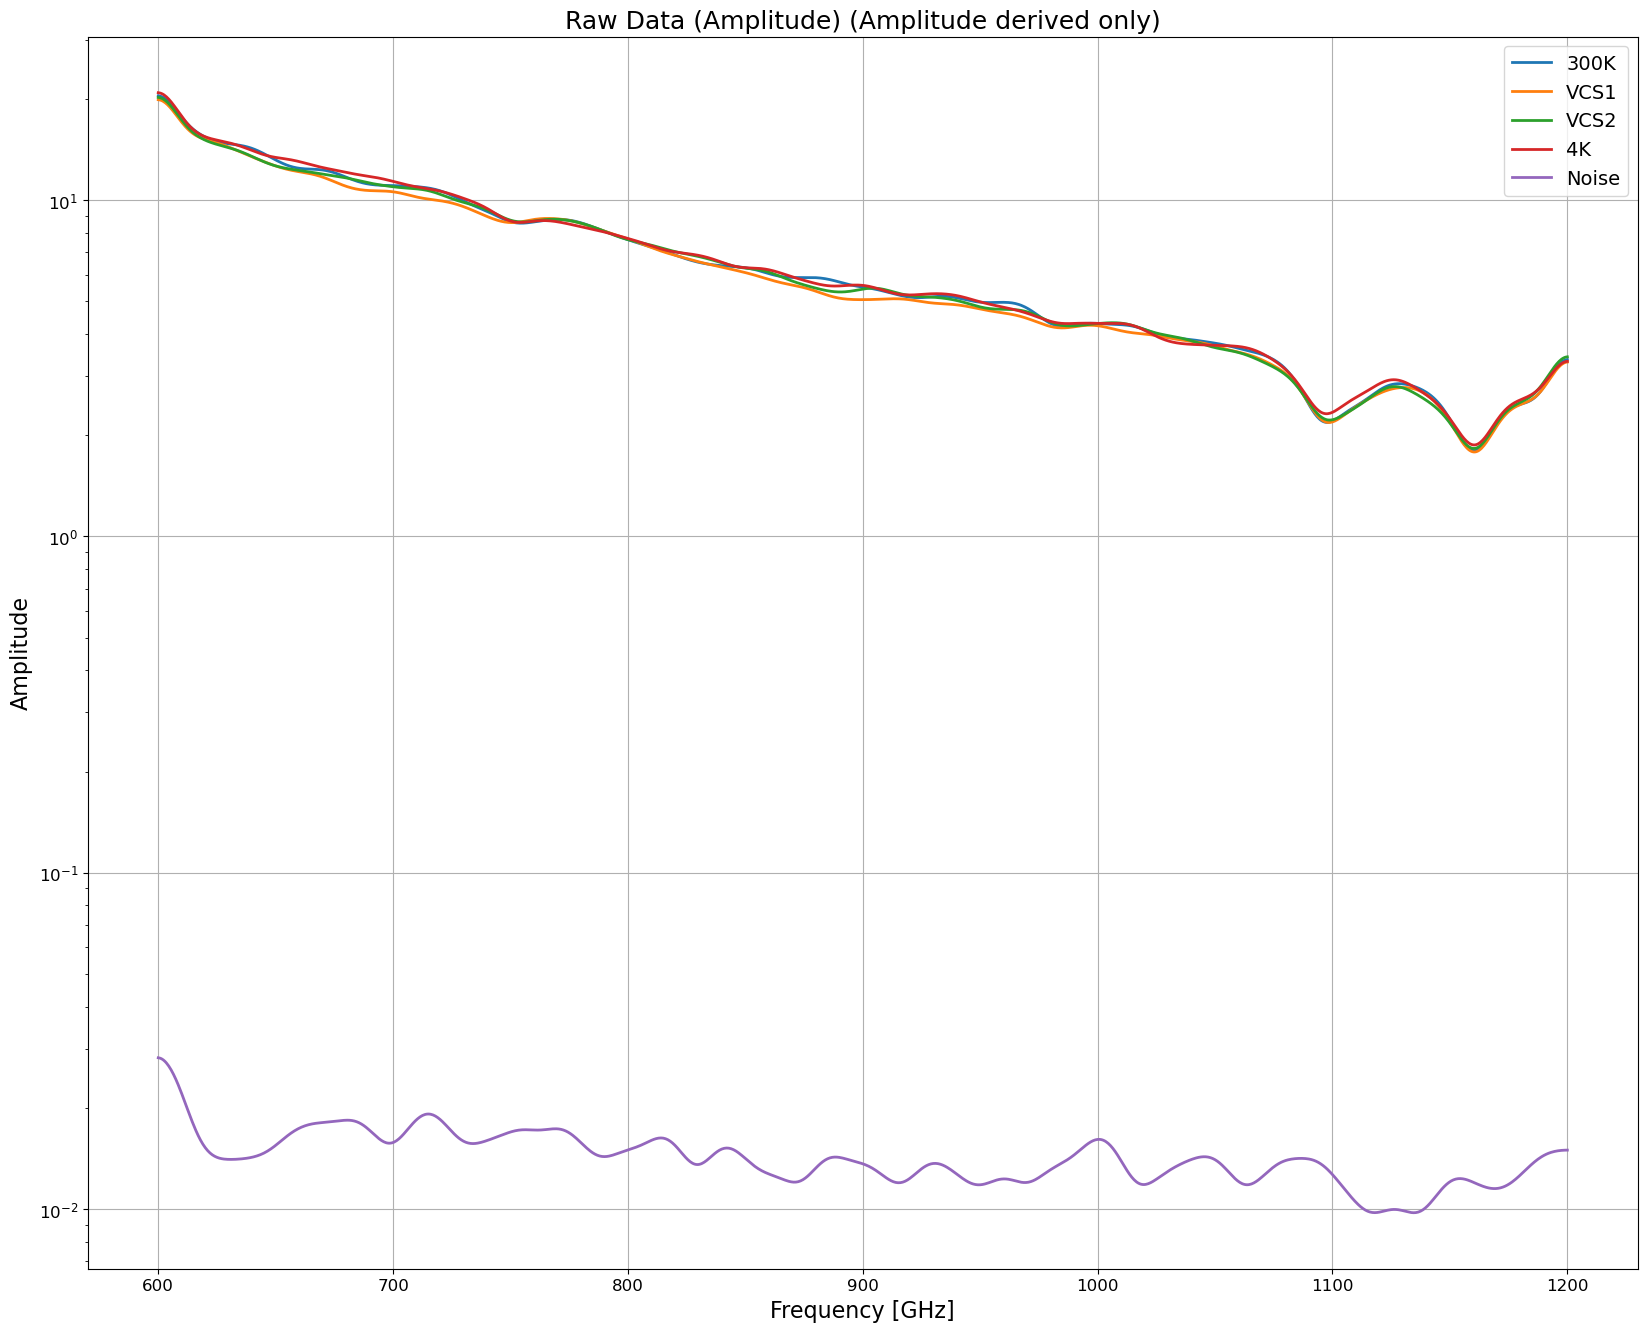

In [25]:
plt.figure(figsize=(20,16))
plt.semilogy(grid_frequencies, np.abs(filter_300K_smooth_amps), label="300K", lw=2)
plt.semilogy(grid_frequencies, np.abs(filter_vcs1_smooth_amps), label="VCS1", lw=2)
plt.semilogy(grid_frequencies, np.abs(filter_vcs2_smooth_amps), label="VCS2", lw=2)
plt.semilogy(grid_frequencies, np.abs(filter_4K_smooth_amps), label="4K", lw=2)
plt.semilogy(grid_frequencies, np.abs(AN72_noise_smooth_amps), label="Noise", lw=2)



plt.legend(fontsize=14)
plt.xlabel("Frequency [GHz]", fontsize = 16)
plt.ylabel(r"Amplitude", fontsize = 16)
plt.title("Raw Data (Amplitude) (Amplitude derived only)", fontsize = 18)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
plt.show()

In [26]:
air1_air2_diff = np.abs(air1_interp_phasor) - np.abs(air2_interp_phasor)
air2_air3_diff = np.abs(air2_interp_phasor) - np.abs(air3_interp_phasor)
air3_air4_diff = np.abs(air3_interp_phasor) - np.abs(air4_interp_phasor)
air4_air5_diff = np.abs(air4_interp_phasor) - np.abs(air5_interp_phasor)

In [ ]:
def freq(freq_PSD, v_FTS):
    c = 299792458
    return (freq_PSD / (2*v_FTS/c))/1e9

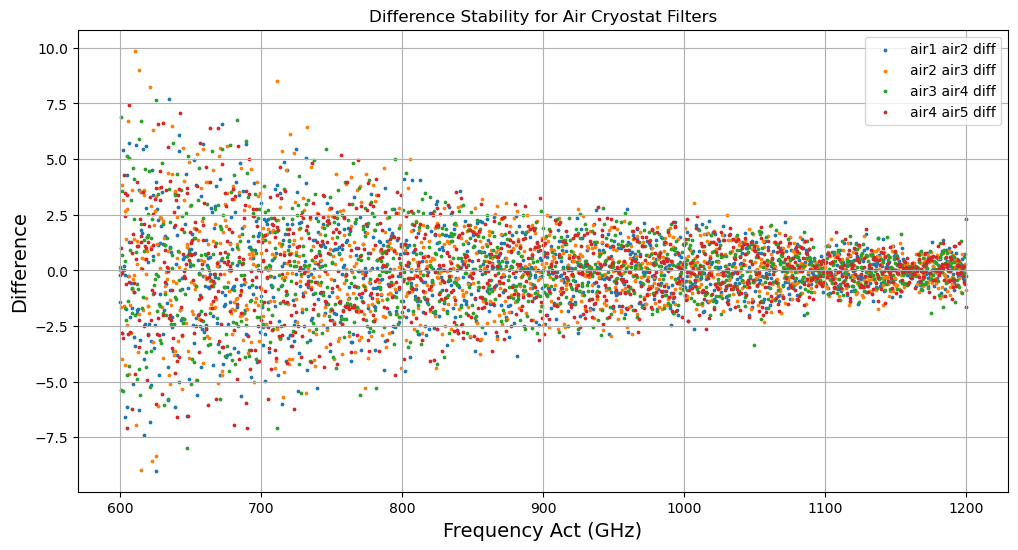

In [27]:
plt.figure(figsize=(12,6))
plt.scatter(grid_frequencies, air1_air2_diff, label="air1 air2 diff", s=3)
plt.scatter(grid_frequencies, air2_air3_diff, label="air2 air3 diff", s=3)
plt.scatter(grid_frequencies, air3_air4_diff, label="air3 air4 diff", s=3)
plt.scatter(grid_frequencies, air4_air5_diff, label="air4 air5 diff", s=3)




plt.xlabel("Frequency Act (GHz)", fontsize=14)
plt.ylabel("Difference", fontsize=14)
plt.legend(fontsize=12)
plt.grid()
plt.title("Difference Stability for Air Cryostat Filters")
plt.legend()
plt.show()

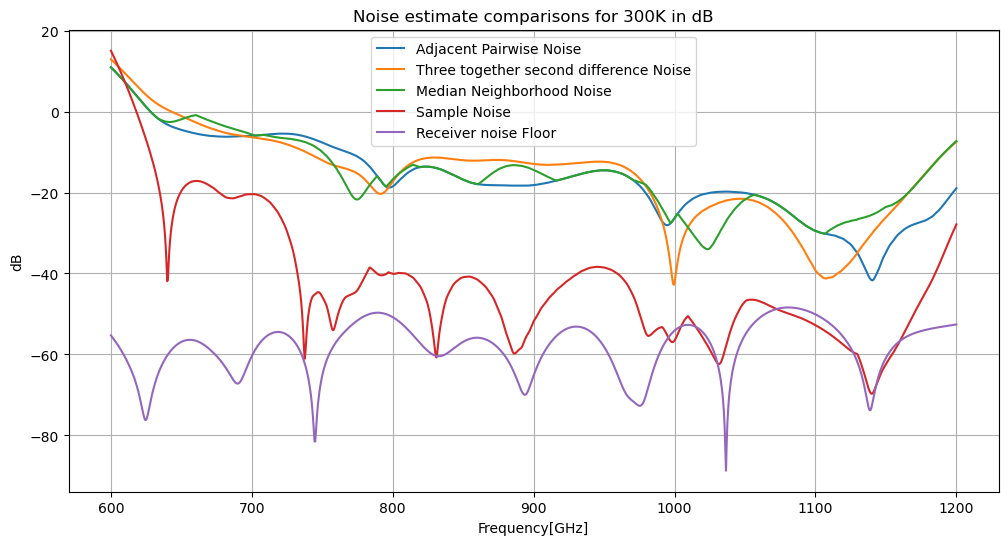

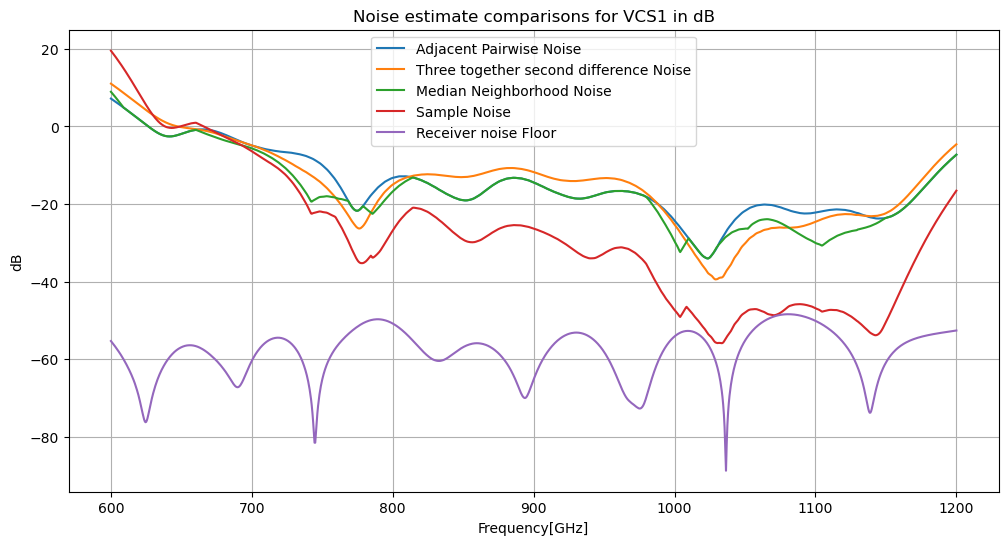

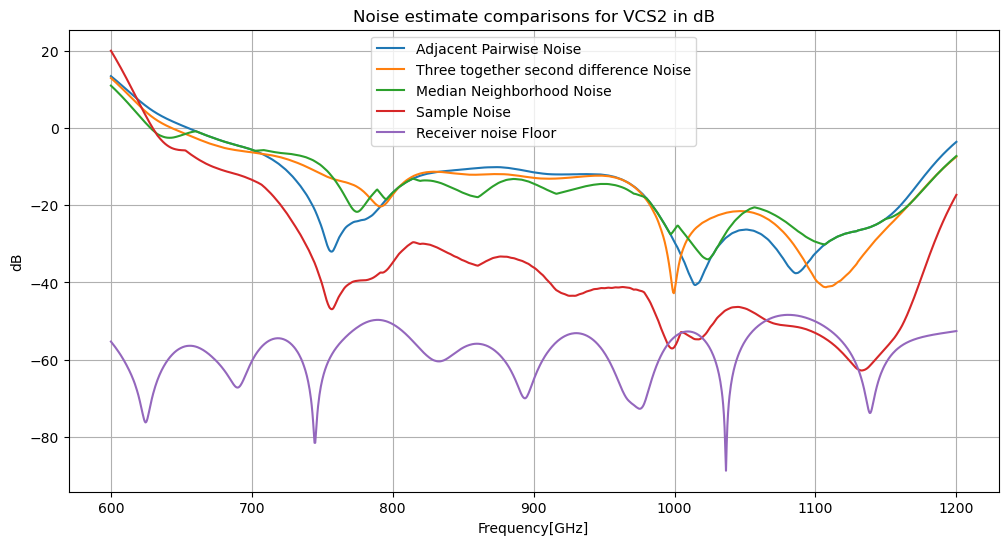

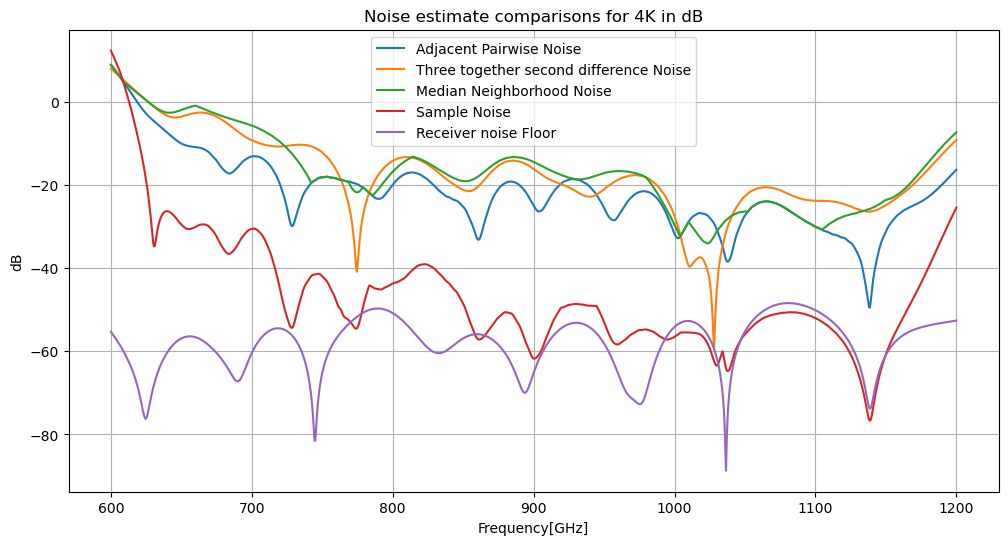

In [33]:
import pickle

ref_arrays = [air1_smooth, air2_smooth, air3_smooth, air4_smooth, air5_smooth]
ref_arrays_amps = [air1_smooth_amps, air2_smooth_amps, air3_smooth_amps, air4_smooth_amps, air5_smooth_amps]
u_sec = np.array([pd.Timestamp(u).value/1e9 for u in u_list], dtype=float)

sample_dict = {
    "300K":(filter_300K_smooth, filter_300K_smooth_amps, t_list[0]),
    "VCS1":(filter_vcs1_smooth, filter_vcs1_smooth_amps, t_list[1]),
    "VCS2":(filter_vcs2_smooth, filter_vcs2_smooth_amps, t_list[2]),
    "4K":(filter_4K_smooth, filter_4K_smooth_amps, t_list[3]),
    # "Noise":(AN72_noise_smooth, AN72_noise_smooth_amps, t_list[4]),
}

for k in list(sample_dict.keys()):
    Z, A, t = sample_dict[k]
    sample_dict[k] = (Z, A, pd.Timestamp(t).value/1e9)

f = np.asarray(grid_frequencies) 
eps = 1e-30

def bracket_indices(u, ts):
    """Return indices (p, n) such that u[p] <= ts <= u[n] (closest bracketing pair).
       Clamps to ends if ts is outside the range."""
    if ts <= u[0]:
        return 0, 1
    if ts >= u[-1]:
        return len(u)-2, len(u)-1
    n = np.searchsorted(u, ts, side="left")
    p = n-1
    return p, n

def three_near(u, ts, p, n):
    """Pick 3 ref indices near ts for second difference:
       prefer (p-1,p,n) if possible, else (p,n,n+1), else closest available 3."""
    idxs = []
    if p-1 >= 0:
        idxs = [p-1, p, n]
    elif n+1 < len(u):
        idxs = [p, n, n+1]
    else:
        # fallback: the last 3 or first 3
        if p >= 1:
            idxs = [p-1, p, n]
        else:
            idxs = [max(0, n-2), max(0, n-1), n]
    return tuple(idxs)

def lin_interp_weights(u_p, u_n, ts):
    """Return (lambda_p, lambda_n) with lambda_p+lambda_n=1 for linear interpolation at ts."""
    denom = (u_n - u_p)
    if np.abs(denom) < 1e-12:
        # times identical (shouldn't happen); fall back to 50-50
        return 0.5, 0.5
    lam_n = (ts - u_p) / denom
    lam_p = 1.0 - lam_n
    return lam_p, lam_n

def second_diff_variance(Ra, Rb, Rc, ua, ub, uc):
    """Drift-killing second-difference variance estimator (B2)."""
    ca, cb, cc = (ub-uc), (uc-ua), (ua-ub)
    denom = (ca**2 + cb**2 + cc**2) + eps
    Delta = ca*Ra + cb*Rb + cc*Rc
    return (np.abs(Delta)**2) / denom  # per frequency vector

def adjacent_variance(Rp, Rn):
    """Adjacent-pair variance estimator (B1)."""
    return 0.5 * np.abs(Rn - Rp)**2  # per frequency vector

def neighborhood_median_adjacent(u, R_list, ts, K=5):
    """Neighborhood-robust median of adjacent pairwise (B3).
       Take K refs closest to ts (at least 3), compute 0.5|R_{i+1}-R_i|^2 and median."""
    # sort refs by |u - ts|
    order = np.argsort(np.abs(u - ts))
    K = max(3, min(K, len(u)))
    idxs = np.sort(order[:K])  # keep time order within window
    # adjacent pairs inside window
    vals = []
    for i0, i1 in zip(idxs[:-1], idxs[1:]):
        vals.append(0.5 * np.abs(R_list[i1] - R_list[i0])**2)  # vector over f
    if len(vals) == 0:
        # fallback: use global adjacent median
        vals = [0.5 * np.abs(R_list[i+1] - R_list[i])**2 for i in range(len(R_list)-1)]
    # stack and take median along 0
    V = np.stack(vals, axis=0)  # shape (pairs, F)
    return np.median(V, axis=0)

# -------- main computation per sample --------
results = {}  

R_all = [np.asarray(R, dtype=np.complex128) for R in ref_arrays]

for name, (S_vec, S_vec_amps, ts) in sample_dict.items():
    S_vec = np.asarray(S_vec, dtype=np.complex128)

    # A) reference at sample time (linear interp of bracketing refs)
    p, n = bracket_indices(u_sec, ts)
    Rp, Rn = R_all[p], R_all[n]
    lam_p, lam_n = lin_interp_weights(u_sec[p], u_sec[n], ts)
    R_ref = lam_p*Rp + lam_n*Rn
    h_j = lam_p**2 + lam_n**2
    R_sq = (np.abs((Rp + Rn)*0.5))**2
    # B1) adjacent variance
    nu_adj = adjacent_variance(Rp, Rn)

    # B2) second-difference (three nearby refs)
    a, b, c = three_near(u_sec, ts, p, n)
    Ra, Rb, Rc = R_all[a], R_all[b], R_all[c]
    nu_sec = second_diff_variance(Ra, Rb, Rc, u_sec[a], u_sec[b], u_sec[c])

    # B3) neighborhood median of adjacent (use 5 closest refs, tweak K as desired)
    nu_med = neighborhood_median_adjacent(u_sec, R_all, ts, K=4)
    c_weight = 1
    nu_hat = np.minimum.reduce([nu_med, nu_adj, nu_sec])    
    nu_hat_sample = ((np.abs(AN72_noise_smooth)**2) + (np.abs((S_vec*np.sqrt(nu_hat)))**2))/2
    # nu_hat = nu_sec

    # biased_powers
    Ps_hat_amp_only = np.abs(S_vec_amps)**2
    Pr_hat_amp_only = np.abs((ref_arrays_amps[p] + ref_arrays_amps[n])/2)**2
    # C) unbiased powers
    Ps_hat = np.abs(S_vec)**2 - nu_hat_sample
    Pr_hat = np.abs(R_ref)**2 - h_j*nu_hat
    # D)  SE for the ratio
    valid = np.isfinite(Pr_hat) & np.isfinite(Ps_hat)

    Trans_unbiased = np.full_like(f, np.nan, dtype=float)
    Trans_unbiased[valid] = Ps_hat[valid] / Pr_hat[valid]
    Trans_biased = Ps_hat_amp_only / Pr_hat_amp_only

    # Variances of unbiased powers
    Var_Ps = 2*nu_hat_sample*np.abs(S_vec)**2 + nu_hat_sample**2
    Var_Pr = (2*(nu_hat*h_j)*np.abs(R_ref)**2) + (nu_hat*h_j)**2

    SE = np.full_like(f, np.nan, dtype=float)
    SE[valid] = np.sqrt( Var_Ps[valid]/(Pr_hat[valid]**2) +
                         (Ps_hat[valid]**2)*Var_Pr[valid]/(Pr_hat[valid]**4) )

    results[name] = {
        "freq_GHz": f.copy(),
        "R_ref": R_ref,
        "h_j": h_j,
        "nu_adj": nu_adj,
        "nu_sec": nu_sec,
        "nu_med": nu_med,
        "nu_hat": nu_hat,
        "nu_hat_sample": nu_hat_sample,
        "Ps_hat": Ps_hat,
        "Pr_hat": Pr_hat,
        "Transmittance_unbiased": Trans_unbiased,
        "Transmittance_biased": Trans_biased,
        "SE": SE,
        "valid_mask": valid,
        "raw_S_sq": np.abs(S_vec)**2, 
        "raw_R_sq" : R_sq
    }



    plt.figure(figsize = (12,6))
    plt.plot(grid_frequencies, 10*np.log10(nu_adj), label = "Adjacent Pairwise Noise")
    plt.plot(grid_frequencies, 10*np.log10(nu_sec), label = "Three together second difference Noise")
    plt.plot(grid_frequencies, 10*np.log10(nu_med), label = "Median Neighborhood Noise")
    plt.plot(grid_frequencies, 10*np.log10(nu_hat_sample), label = "Sample Noise")
    plt.plot(grid_frequencies, 10*np.log10(np.abs(AN72_noise_smooth)**2), label = "Receiver noise Floor")
    plt.grid()
    plt.legend()
    plt.ylabel("dB")
    plt.title(f"Noise estimate comparisons for {name} in dB")
    plt.xlabel("Frequency[GHz]")
    plt.show()
    
with open("transmittance_results.pkl", "wb") as f_out:
    pickle.dump(results, f_out)

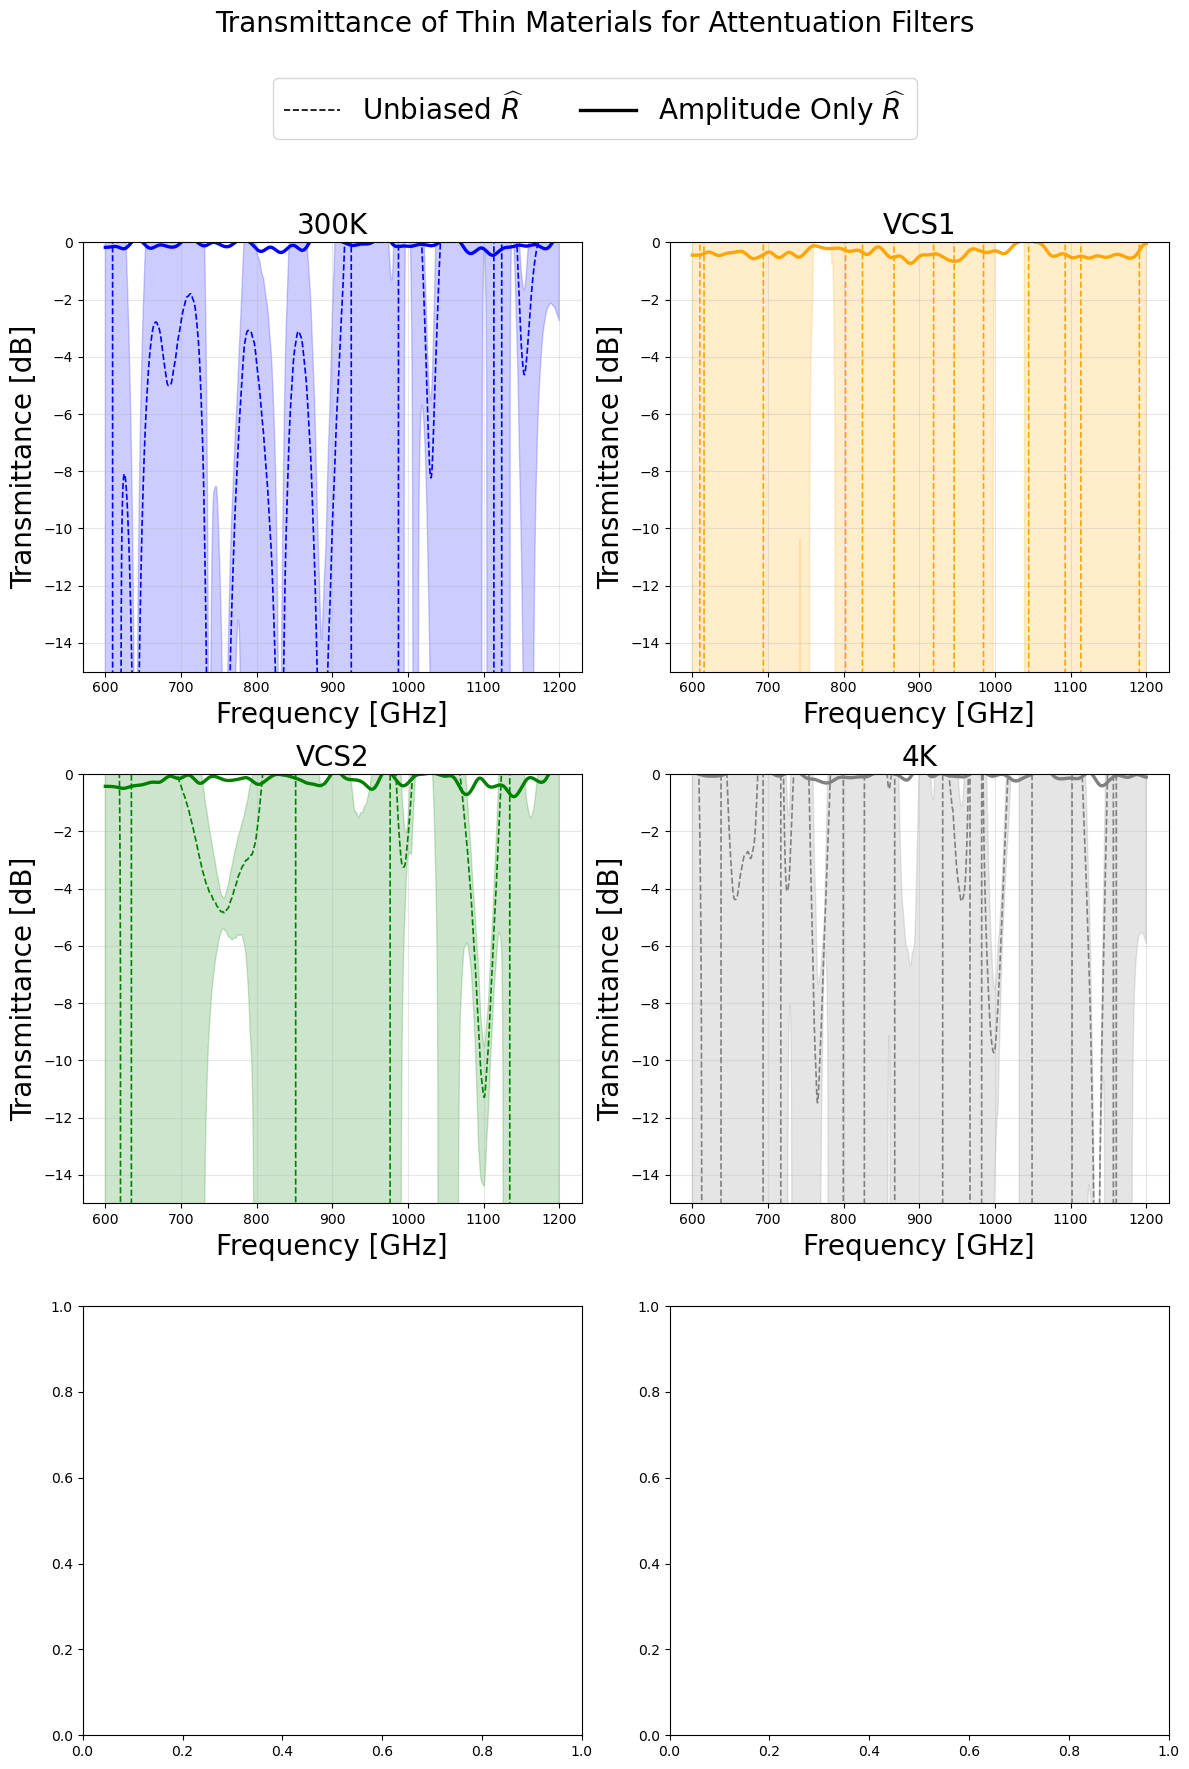

In [34]:
fig, axes = plt.subplots(3, 2, figsize=(12, 18))  
axes = axes.flatten()  
colors = ["blue", "orange", "green", "gray", "purple", "fuchsia"]
# samples = [ "Double Al",  "Single Al (Cond)", "Single Al (Insu)"]

for idx, (name, (S_vec, S_vec_amps, ts)) in enumerate(sample_dict.items()):
    Amp_transmittance = results[name]["Transmittance_biased"]
    transmittance_unb = results[name]["Transmittance_unbiased"]  
    SE_R = results[name]["SE"]
    lo = np.clip(transmittance_unb - 1.96*SE_R, 1e-20, None)
    hi = np.clip(transmittance_unb + 1.96*SE_R, 1e-20, None)
    # lo = reflectance_unb - 3*SE_R
    # hi = reflectance_unb + 3*SE_R
    lo_dB, hi_dB  = 10 * np.log10(lo), 10 * np.log10(hi)
    T_ampcurve_dB = 10 * np.log10(Amp_transmittance)
    T_unbiased_dB = 10 * np.log10(np.clip(transmittance_unb, 1e-20, None))
    
    ax = axes[idx]  
    ax.plot(grid_frequencies, T_unbiased_dB, c=colors[idx], lw=1.2, ls="--")
    ax.plot(grid_frequencies, T_ampcurve_dB, c=colors[idx], lw=2.4)
    ax.fill_between(grid_frequencies, lo_dB, hi_dB, color=colors[idx], alpha=0.2)
    ax.set_xlabel("Frequency [GHz]", fontsize = 20)
    ax.set_ylabel("Transmittance [dB]", fontsize = 20)
    ax.set_ylim(-15, 0)
    ax.set_title(f"{name}", fontsize = 20)
    ax.grid(True, which="both", alpha=0.3)

fig.legend(
    handles=[
        plt.Line2D([0], [0], color="k", lw=1.2, ls="--", label=r"Unbiased $\widehat{R}$"),
        plt.Line2D([0], [0], color="k", lw=2.4, label=r"Amplitude Only $\widehat{R}$"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.95),
    ncol=2,
    fontsize=20,
)
fig.suptitle("Transmittance of Thin Materials for Attentuation Filters", fontsize=20)
fig.subplots_adjust(top=0.00098, bottom=0.0001) 
plt.tight_layout(rect=[0, 0, 1, 0.9]) 
plt.show()

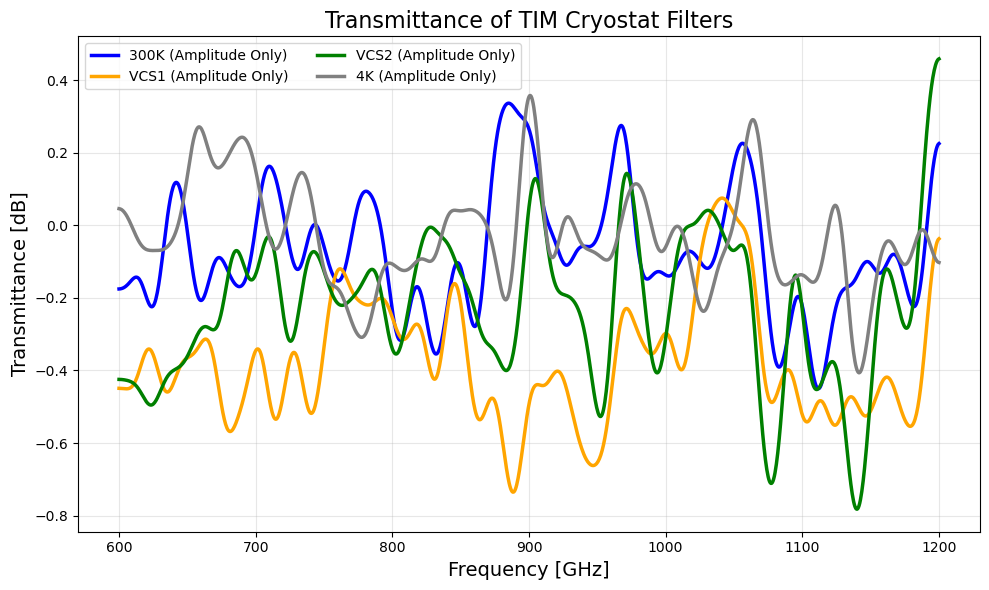

In [35]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = ["blue", "orange", "green", "gray", "purple", "fuchsia"]

for idx, (name, (S_vec, S_vec_amps, ts)) in enumerate(sample_dict.items()):
    Amp_transmittance = results[name]["Transmittance_biased"]
    transmittance_unb = results[name]["Transmittance_unbiased"]

    T_amp_percent = np.log10(Amp_transmittance)*10
    T_unb_percent = 100 * transmittance_unb

    # Plot both curves
#     ax.plot(grid_frequencies, T_unb_percent,
#             color=colors[idx], lw=1.5, ls="--",
#             label=f"{name} (Unbiased)")

    ax.plot(grid_frequencies, T_amp_percent,
            color=colors[idx], lw=2.5,
            label=f"{name} (Amplitude Only)")

# x = np.arange(600, 1200, 10)
# y1 = 100
# y2 = 110

# ax.fill_between(x, y1, y2, label = "Nobel Prize Winning Region", color="lightgray", alpha=1)

ax.set_xlabel("Frequency [GHz]", fontsize=14)
ax.set_ylabel("Transmittance [dB]", fontsize=14)

ax.grid(True, which="both", alpha=0.3)
ax.fill

ax.set_title("Transmittance of TIM Cryostat Filters", fontsize=16)
ax.legend(fontsize=10, ncol=2)
plt.tight_layout()
plt.show()

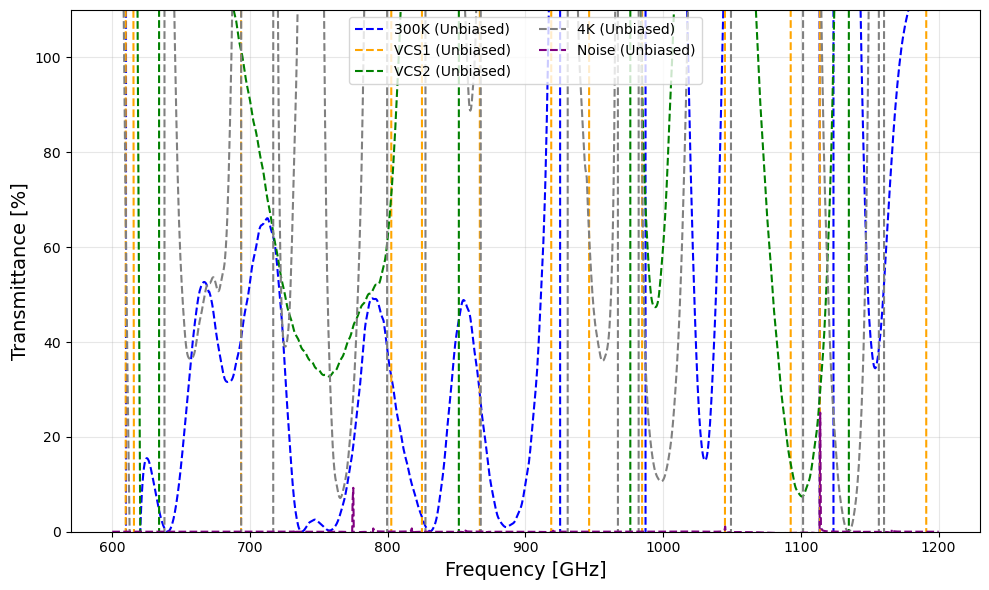

In [31]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = ["blue", "orange", "green", "gray", "purple", "fuchsia"]

for idx, (name, (S_vec, S_vec_amps, ts)) in enumerate(sample_dict.items()):
    Amp_transmittance = results[name]["Transmittance_biased"]
    transmittance_unb = results[name]["Transmittance_unbiased"]

    # Convert to percent
    T_amp_percent = 100 * Amp_transmittance
    T_unb_percent = 100 * transmittance_unb

    # Plot both curves
    ax.plot(grid_frequencies, T_unb_percent,
            color=colors[idx], lw=1.5, ls="--",
            label=f"{name} (Unbiased)")

    # ax.plot(grid_frequencies, T_amp_percent,
    #         color=colors[idx], lw=2.5,
    #         label=f"{name} (Amplitude Only)")

# Labels and styling
ax.set_xlabel("Frequency [GHz]", fontsize=14)
ax.set_ylabel("Transmittance [%]", fontsize=14)

ax.grid(True, which="both", alpha=0.3)

# Optional: adjust y-limits depending on your data
ax.set_ylim(0, 110)

ax.legend(fontsize=10, ncol=2)
plt.tight_layout()
plt.show()